# Learning Vector Quantization (LVQ) Lab
**Name:** Niha batool
**Reg no:** Fa23-bai-042

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository: 569 samples, 30 numeric features, 2 classes (malignant / benign).

*Note: the task text says "SOMs" but the title says LVQ, so this notebook implements LVQ (LVQ1), a supervised relative of the SOM.*

## 1. Load and preprocess the data

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_breast_cancer()                       # UCI dataset
X, y = data.data, data.target
print("Shape:", X.shape, "| Missing:", np.isnan(X).sum(), "| Class counts:", np.bincount(y))

# 80/20 split, stratified so both sets keep the same class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Standardize using TRAIN statistics only (avoids data leakage into the test set)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

Shape: (569, 30) | Missing: 0 | Class counts: [212 357]


## 2. LVQ1 implementation (from scratch)

In [2]:
class LVQ:
    def __init__(self, n_per_class=3, lr0=0.3, epochs=30, seed=42):
        self.n, self.lr0, self.epochs = n_per_class, lr0, epochs
        self.rng = np.random.default_rng(seed)

    def predict(self, X):
        # Label of the nearest prototype (Euclidean distance)
        D = np.linalg.norm(X[:, None, :] - self.P[None], axis=2)
        return self.PL[D.argmin(axis=1)]

    def fit(self, X, y):
        # Initialise prototypes: random training samples of each class
        P, PL = [], []
        for c in np.unique(y):
            idx = self.rng.choice(np.where(y == c)[0], self.n, replace=False)
            P.append(X[idx]); PL += [c] * self.n
        self.P, self.PL = np.vstack(P).astype(float), np.array(PL)
        self.history = []                                  # training accuracy per epoch

        T, t = self.epochs * len(X), 0
        for ep in range(self.epochs):
            for i in self.rng.permutation(len(X)):         # shuffle samples each epoch
                lr = self.lr0 * (1 - t / T); t += 1        # learning rate decays linearly
                j = np.linalg.norm(self.P - X[i], axis=1).argmin()   # winning prototype
                if self.PL[j] == y[i]:
                    self.P[j] += lr * (X[i] - self.P[j])   # same class: move closer
                else:
                    self.P[j] -= lr * (X[i] - self.P[j])   # different class: push away
            self.history.append(accuracy_score(y, self.predict(X)))
        return self

## 3. Train the model

In [3]:
lvq = LVQ(n_per_class=3, lr0=0.3, epochs=30).fit(X_train, y_train)

train_acc = accuracy_score(y_train, lvq.predict(X_train))
test_acc  = accuracy_score(y_test,  lvq.predict(X_test))
print(f"Train accuracy: {train_acc:.3f}")
print(f"Test accuracy : {test_acc:.3f}")

Train accuracy: 0.945
Test accuracy : 0.939


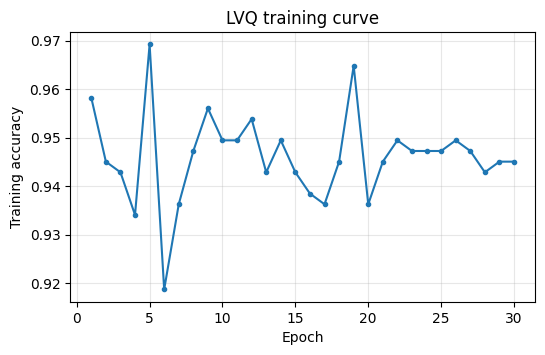

In [4]:
# Training curve
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, 31), lvq.history, marker='o', ms=3)
plt.xlabel('Epoch'); plt.ylabel('Training accuracy'); plt.title('LVQ training curve')
plt.grid(alpha=0.3); plt.show()

## 4. Evaluation

In [5]:
y_pred = lvq.predict(X_test)
print("Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=data.target_names, digits=3))

Confusion matrix (rows = true, cols = predicted):
 [[37  5]
 [ 2 70]]
              precision    recall  f1-score   support

   malignant      0.949     0.881     0.914        42
      benign      0.933     0.972     0.952        72

    accuracy                          0.939       114
   macro avg      0.941     0.927     0.933       114
weighted avg      0.939     0.939     0.938       114



 1 prototypes/class -> test accuracy 0.947
 2 prototypes/class -> test accuracy 0.921
 3 prototypes/class -> test accuracy 0.939
 5 prototypes/class -> test accuracy 0.956
10 prototypes/class -> test accuracy 0.956


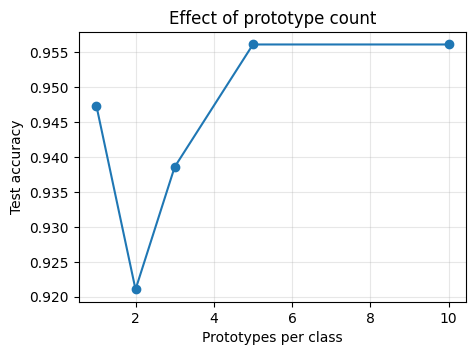

In [6]:
# Effect of the number of prototypes per class
sizes = [1, 2, 3, 5, 10]
accs = [accuracy_score(y_test, LVQ(n_per_class=n).fit(X_train, y_train).predict(X_test)) for n in sizes]
for n, a in zip(sizes, accs): print(f"{n:>2} prototypes/class -> test accuracy {a:.3f}")

plt.figure(figsize=(5, 3.5))
plt.plot(sizes, accs, marker='o'); plt.xlabel('Prototypes per class'); plt.ylabel('Test accuracy')
plt.title('Effect of prototype count'); plt.grid(alpha=0.3); plt.show()

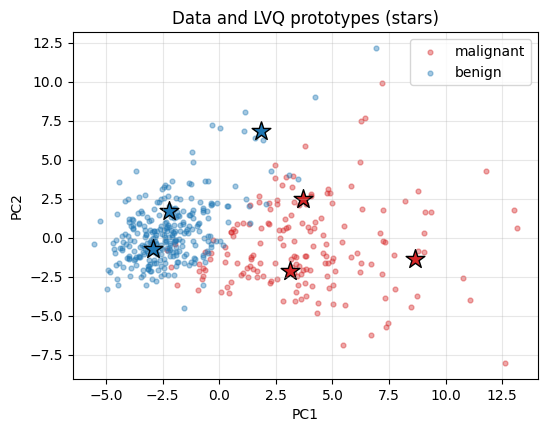

In [7]:
# Visualize data and learned prototypes in 2D using PCA
pca = PCA(n_components=2).fit(X_train)
Z, Zp = pca.transform(X_train), pca.transform(lvq.P)
plt.figure(figsize=(6, 4.5))
for c, col, name in [(0, 'tab:red', 'malignant'), (1, 'tab:blue', 'benign')]:
    plt.scatter(Z[y_train == c, 0], Z[y_train == c, 1], c=col, s=12, alpha=0.4, label=name)
    plt.scatter(Zp[lvq.PL == c, 0], Zp[lvq.PL == c, 1], c=col, s=200, marker='*', edgecolors='k')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Data and LVQ prototypes (stars)')
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
# Report

## 1. Data preprocessing
- Loaded the UCI **Breast Cancer Wisconsin** dataset (569 samples, 30 features; 212 malignant, 357 benign). No missing values.
- Split into **80% train / 20% test**, stratified to keep the class ratio.
- **Standardized** all features (zero mean, unit variance). LVQ classifies by Euclidean distance, so features with large ranges (e.g. area) would otherwise dominate. The scaler was fitted on the training set only, to avoid data leakage.

## 2. Model architecture and hyperparameters
LVQ1 is a set of labelled **prototype vectors**; a sample gets the label of its nearest prototype.

| Parameter | Value | Reason |
|---|---|---|
| Prototypes per class | 3 (6 total) | One prototype per class is too simple for classes with several sub-groups; more prototypes add complexity with little gain (see results) |
| Initialisation | Random training samples of each class | Starts prototypes inside the correct class region |
| Learning rate | 0.3, decaying linearly to 0 | Fast adaptation early, stable fine-tuning at the end |
| Epochs | 30 | Training accuracy stops improving well before this |
| Distance | Euclidean | Suitable for standardized numeric data |

**Update rule:** for each sample, find the nearest prototype *w*. If its class matches the sample, *w ← w + η(x − w)* (attract); otherwise *w ← w − η(x − w)* (repel).

## 3. Training process and evaluation metrics
Samples were shuffled each epoch and the prototypes updated one sample at a time. Results on the **held-out test set (114 samples)**:
- **Train accuracy:** 94.5%, **Test accuracy:** 93.9%
- **Confusion matrix:** 37 malignant and 70 benign correct; 5 malignant predicted as benign, 2 benign predicted as malignant.
- **Malignant:** precision 0.949, recall 0.881, F1 0.914. **Benign:** precision 0.933, recall 0.972, F1 0.952.
- **Prototype count:** test accuracy was 94.7% (1), 92.1% (2), 93.9% (3), 95.6% (5) and 95.6% (10 per class).

**Observations:**
- With only 6 prototypes, LVQ reaches about 94% test accuracy, and train and test accuracy are close, so there is no sign of overfitting.
- The training curve is fairly flat and noisy: it starts high (about 96%) because the data is easy to separate and prototypes start inside the right classes.
- The model misses more malignant cases (recall 88%) than benign ones (97%). In a medical setting, missed malignant cases are the costlier error, so this would need attention.
- The prototype count changes test accuracy by only a few samples (1 sample is about 0.9% of the test set), so the differences between 1 and 10 prototypes are within noise. 3 per class is a reasonable, simple choice.